14529
label
Tomato___Tomato_Yellow_Leaf_Curl_Virus           4286
Tomato___Bacterial_spot                          1702
Tomato___Late_blight                             1527
Tomato___Septoria_leaf_spot                      1417
Tomato___Spider_mites Two-spotted_spider_mite    1341
Tomato___healthy                                 1273
Tomato___Target_Spot                             1123
Tomato___Early_blight                             800
Tomato___Leaf_Mold                                761
Tomato___Tomato_mosaic_virus                      299
Name: count, dtype: int64


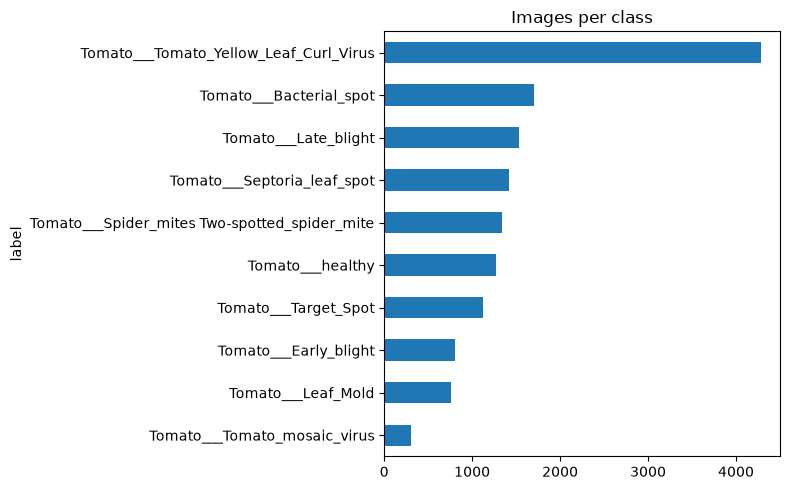

Imbalance ratio: 14.3


In [2]:
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt, random
from PIL import Image

DATA_DIR = Path("../data/tomato")
rows = []
for cls_dir in sorted(DATA_DIR.iterdir()):
    for p in cls_dir.glob("*"):
        if p.suffix.lower() in {".jpg", ".jpeg", ".png"}:
            rows.append({"path": str(p), "label": cls_dir.name})
df = pd.DataFrame(rows)
print(len(df))
counts = df["label"].value_counts()
print(counts)
counts.sort_values().plot(kind="barh", figsize=(8, 5), title="Images per class")
plt.tight_layout(); plt.show()
print("Imbalance ratio:", round(counts.max() / counts.min(), 1))

In [3]:
sample = df.sample(300, random_state=42)
sizes = [Image.open(p).size for p in sample["path"]]
print(pd.Series(sizes).value_counts().head())
print(df["path"].str.extract(r"(\.\w+)$")[0].str.lower().value_counts())

(256, 256)    300
Name: count, dtype: int64
0
.jpg     14528
.jpeg        1
Name: count, dtype: int64


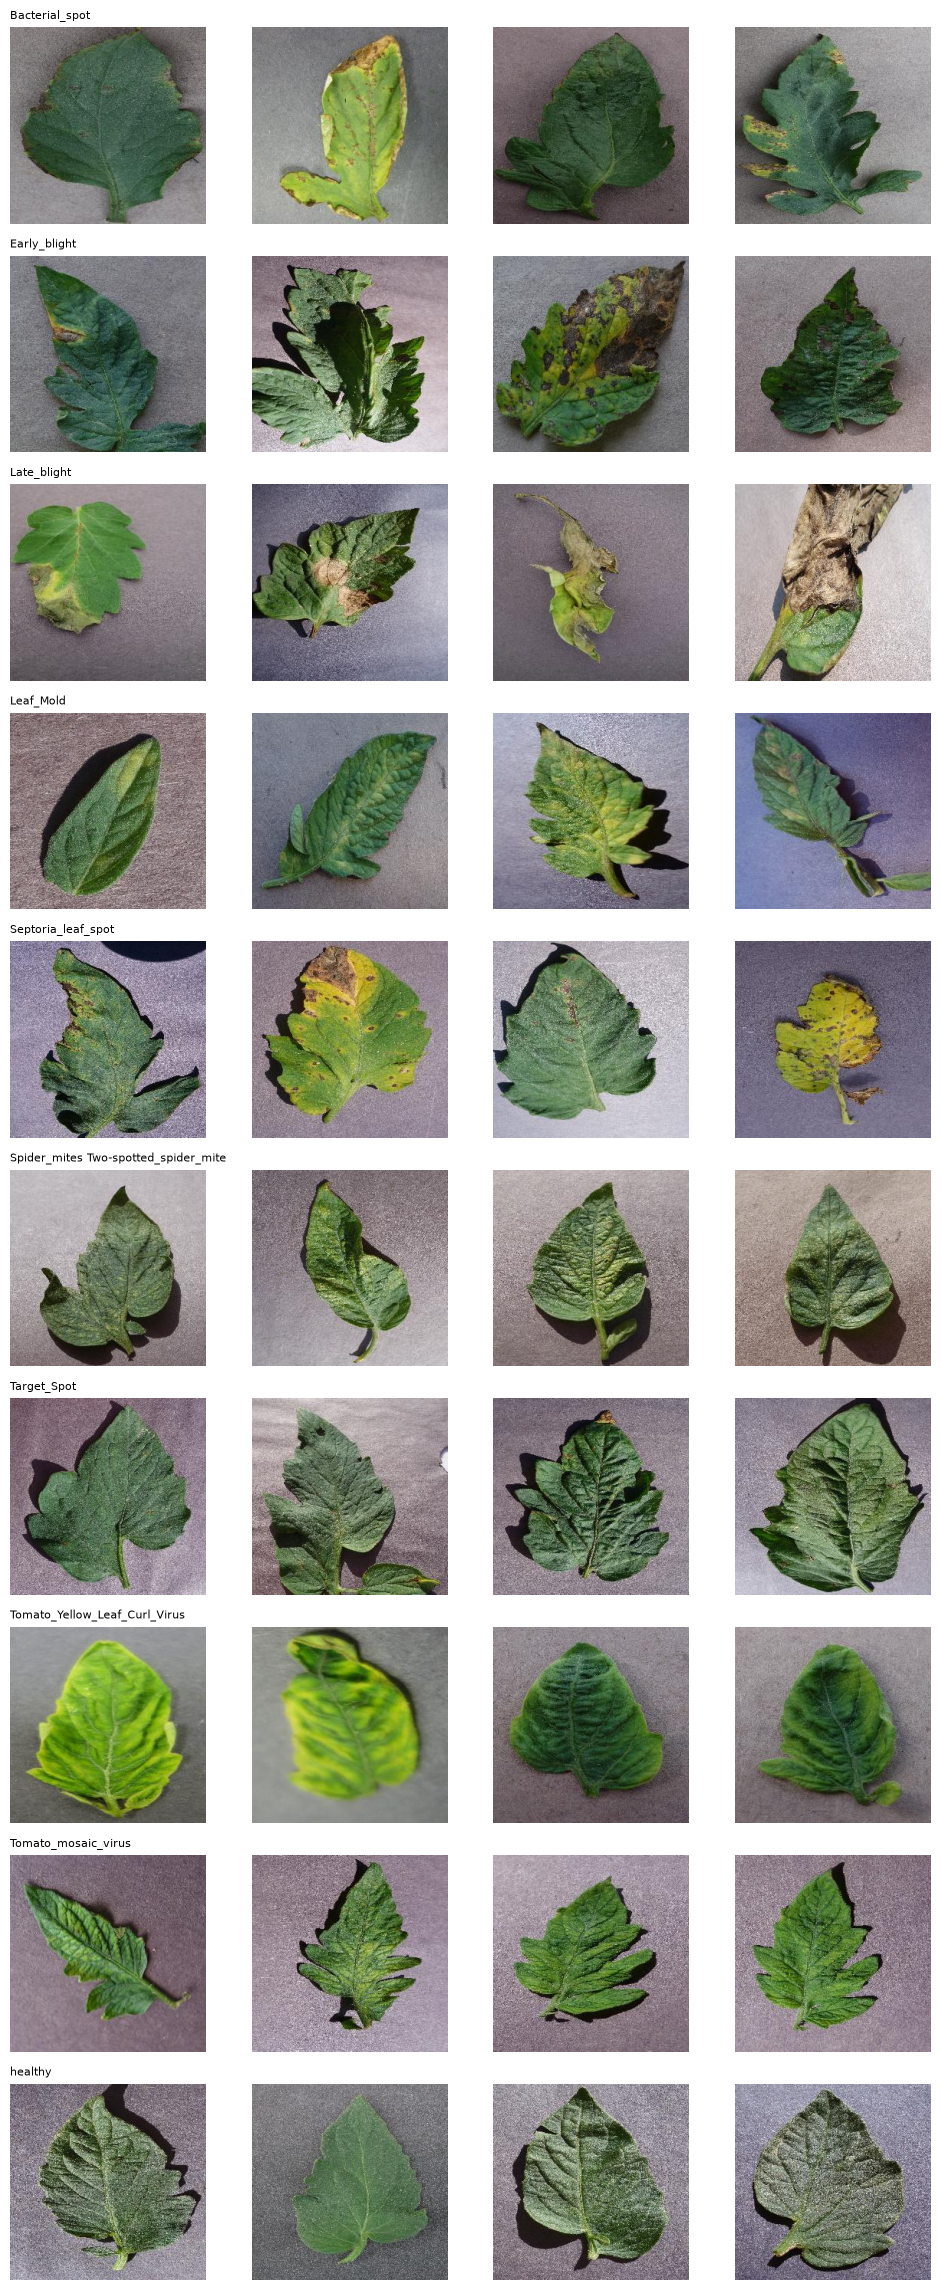

In [4]:
classes = sorted(df["label"].unique())
fig, axes = plt.subplots(len(classes), 4, figsize=(10, 2.3 * len(classes)))
for i, c in enumerate(classes):
    imgs = random.Random(0).sample(df[df.label == c]["path"].tolist(), 4)
    for j, p in enumerate(imgs):
        axes[i, j].imshow(Image.open(p)); axes[i, j].axis("off")
    axes[i, 0].set_title(c.replace("Tomato___", ""), fontsize=8, loc="left")
plt.tight_layout(); plt.show()

In [5]:
for c in classes[:3]:
    print(c)
    print(df[df.label == c]["path"].map(lambda p: Path(p).name).head(8).tolist())
print("Suspicious names:",
      df["path"].str.contains("flip|deg|rot|mirror|aug", case=False).sum())

Tomato___Bacterial_spot
['00416648-be6e-4bd4-bc8d-82f43f8a7240___GCREC_Bact.Sp 3110.JPG', '0045ba29-ed1b-43b4-afde-719cc7adefdb___GCREC_Bact.Sp 6254.JPG', '00639d29-2d1a-4fcf-9bd3-a2b3109c74c4___UF.GRC_BS_Lab Leaf 1054.JPG', '00a7c269-3476-4d25-b744-44d6353cd921___GCREC_Bact.Sp 5807.JPG', '00b7e89a-e129-4576-b51f-48923888bff9___GCREC_Bact.Sp 6202.JPG', '01375198-62af-4c40-bddf-f3c11107200b___GCREC_Bact.Sp 5914.JPG', '014b58ae-091b-408a-ab4a-5a780cd1c3f3___GCREC_Bact.Sp 2971.JPG', '01a3cf3f-94c1-44d5-8972-8c509d62558e___GCREC_Bact.Sp 3396.JPG']
Tomato___Early_blight
['0012b9d2-2130-4a06-a834-b1f3af34f57e___RS_Erly.B 8389.JPG', '004cbe60-8ff9-4965-92df-e86694d5e9ba___RS_Erly.B 8253.JPG', '00c5c908-fc25-4710-a109-db143da23112___RS_Erly.B 7778.JPG', '0114f7b3-7f56-4bef-aa47-7a82da142d4b___RS_Erly.B 7437.JPG', '0208ed52-1b28-4c9c-88e3-4667581e1109___RS_Erly.B 7829.JPG', '023fe2d4-6e1d-40ce-99ae-85ba90f436ff___RS_Erly.B 6354.JPG', '0378db62-5231-4eff-815d-c0deb0043e80___RS_Erly.B 7464.JPG', 

In [8]:
import hashlib
def file_hash(p):
    with open(p, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()
df["hash"] = df["path"].map(file_hash)
print("Exact duplicates:", df["hash"].duplicated().sum())

Exact duplicates: 9


In [9]:
import re
df["source"] = df["path"].map(
    lambda p: re.sub(r"\s*\d+\.\w+$", "", Path(p).name.split("___", 1)[-1]))
print("Distinct sources:", df["source"].nunique())

summary = df.groupby("label")["source"].agg(
    n_sources="nunique",
    top_source=lambda s: s.value_counts().index[0],
    top_share=lambda s: round(s.value_counts(normalize=True).iloc[0], 2),
)
print(summary)

Distinct sources: 402
                                               n_sources       top_source  \
label                                                                       
Tomato___Bacterial_spot                                2    GCREC_Bact.Sp   
Tomato___Early_blight                                  1        RS_Erly.B   
Tomato___Late_blight                                 203        RS_Late.B   
Tomato___Leaf_Mold                                     1      Crnl_L.Mold   
Tomato___Septoria_leaf_spot                            3        Matt.S_CG   
Tomato___Spider_mites Two-spotted_spider_mite          1     Com.G_SpM_FL   
Tomato___Target_Spot                                   1     Com.G_TgS_FL   
Tomato___Tomato_Yellow_Leaf_Curl_Virus                 3  UF.GRC_YLCV_Lab   
Tomato___Tomato_mosaic_virus                           1           PSU_CG   
Tomato___healthy                                     188            RS_HL   

                                               top_sh

In [10]:
dups = df[df["hash"].duplicated(keep=False)].sort_values("hash")
print(dups.groupby("hash")["label"].nunique().value_counts())

label
1    9
Name: count, dtype: int64
